# Description

Gap analysis of the 5-minute Binance data (#904), as asked by GP on #733.
Data cleanliness only: how many gaps there are, when they happen, and how
much data each cleaning step costs.

- BTC and ETH, 5-minute bars, 2020-01-01 to 2026-10-01, cleaned with
  `clean_bars()`, so zero-volume bars right before a gap are part of the
  gap (`D15`)
- All times are in UTC

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

import data_utils as dutil
import matplotlib.pyplot as plt
import pandas as pd

## Config

In [2]:
SYMBOLS = ["BTCUSDT", "ETHUSDT"]
INTERVAL = "5m"
START = "2020-01-01"
END = "2026-10-01"
HORIZONS = ["5m", "15m", "1h", "4h", "1d"]

## Load and clean

In [3]:
raw = {}
clean = {}
for symbol in SYMBOLS:
    raw[symbol] = dutil.load_ohlcv(symbol, START, END, interval=INTERVAL)
    clean[symbol] = dutil.clean_bars(raw[symbol], interval=INTERVAL)

## Gaps

One row per run of missing bars, with the stale bars before it.

In [4]:
gaps = {
    symbol: dutil.compute_gap_table(clean[symbol], interval=INTERVAL)
    for symbol in SYMBOLS
}
gaps["BTCUSDT"]

,start,end,n_bars,n_stale,duration,is_filled
0,2020-02-09 02:00:00+00:00,2020-02-09 02:55:00+00:00,12,0,0 days 01:00:00,False
1,2020-02-19 11:40:00+00:00,2020-02-19 17:25:00+00:00,70,0,0 days 05:50:00,False
2,2020-03-04 09:25:00+00:00,2020-03-04 11:25:00+00:00,25,0,0 days 02:05:00,False
3,2020-04-25 02:00:00+00:00,2020-04-25 04:25:00+00:00,30,0,0 days 02:30:00,False
4,2020-06-28 02:00:00+00:00,2020-06-28 05:25:00+00:00,42,0,0 days 03:30:00,False
5,2020-11-30 06:00:00+00:00,2020-11-30 06:55:00+00:00,12,0,0 days 01:00:00,False
6,2020-12-21 13:20:00+00:00,2020-12-21 17:55:00+00:00,56,10,0 days 04:40:00,False
7,2020-12-25 02:00:00+00:00,2020-12-25 02:55:00+00:00,12,0,0 days 01:00:00,False
8,2021-02-11 02:20:00+00:00,2021-02-11 04:55:00+00:00,32,17,0 days 02:40:00,False
9,2021-03-06 02:00:00+00:00,2021-03-06 03:25:00+00:00,18,0,0 days 01:30:00,False


In [5]:
# Check that BTC and ETH have the gaps at the same times.
cols = ["start", "end", "n_bars", "n_stale"]
same = gaps["BTCUSDT"][cols].equals(gaps["ETHUSDT"][cols])
print(f"Same gaps for BTC and ETH: {same}")

Same gaps for BTC and ETH: True


## Gaps per year

In [6]:
df = gaps["BTCUSDT"]
per_year = df.groupby(df["start"].dt.year).agg(
    n_gaps=("n_bars", "size"),
    n_missing_bars=("n_bars", "sum"),
    n_stale_bars=("n_stale", "sum"),
    total_time=("duration", "sum"),
    longest=("duration", "max"),
)
per_year = per_year.reindex(range(2020, 2027), fill_value=0)
per_year

,n_gaps,n_missing_bars,n_stale_bars,total_time,longest
start,,,,,
2020,8,259,10,0 days 21:35:00,0 days 05:50:00
2021,6,214,17,0 days 17:50:00,0 days 04:40:00
2022,0,0,0,0,0
2023,1,30,14,0 days 02:30:00,0 days 02:30:00
2024,0,0,0,0,0
2025,0,0,0,0,0
2026,0,0,0,0,0


## When gaps start

Hour of day and day of week of the first missing bar.

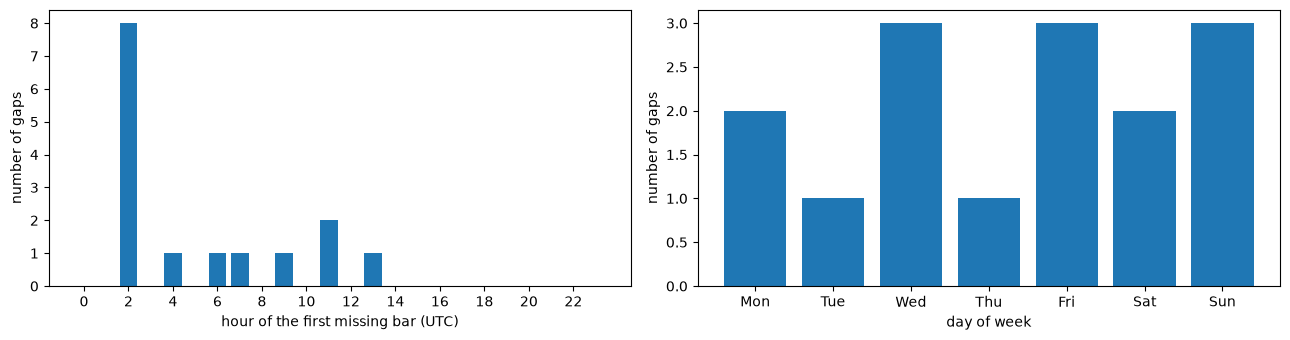

In [7]:
start = gaps["BTCUSDT"]["start"]
by_hour = start.dt.hour.value_counts().reindex(range(24), fill_value=0)
days = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]
by_day = start.dt.day_name().value_counts().reindex(days, fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].bar(by_hour.index, by_hour.to_numpy())
axes[0].set_xlabel("hour of the first missing bar (UTC)")
axes[0].set_ylabel("number of gaps")
axes[0].set_xticks(range(0, 24, 2))
axes[1].bar(by_day.index.str[:3], by_day.to_numpy())
axes[1].set_xlabel("day of week")
axes[1].set_ylabel("number of gaps")
plt.tight_layout()

## Timeline

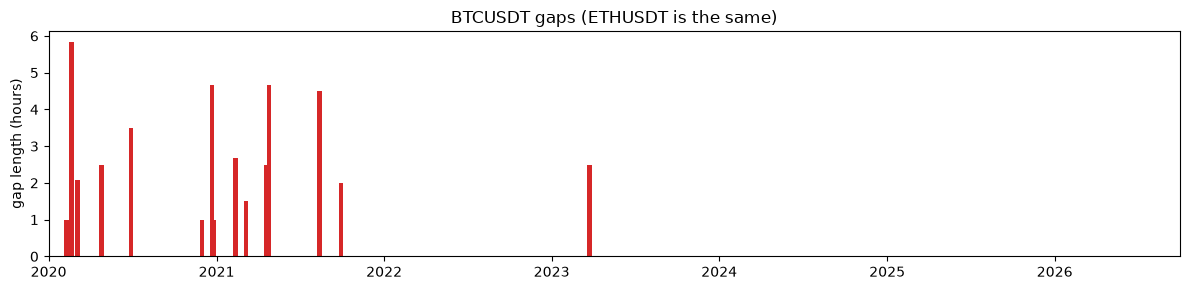

In [8]:
fig, ax = plt.subplots(figsize=(12, 3))
df = gaps["BTCUSDT"]
hours = df["duration"].dt.total_seconds() / 3600
ax.bar(df["start"], hours, width=10, color="C3")
ax.set_ylabel("gap length (hours)")
ax.set_xlim(pd.Timestamp(START, tz="UTC"), pd.Timestamp(END, tz="UTC"))
ax.set_title("BTCUSDT gaps (ETHUSDT is the same)")
plt.tight_layout()

## Zero-volume bars that are not before a gap

In [9]:
for symbol in SYMBOLS:
    df = clean[symbol]
    t = df.index[df["is_zero_volume"]]
    print(symbol, t.tolist())
# Look at the bars around the one on BTC.
t = clean["BTCUSDT"].index[clean["BTCUSDT"]["is_zero_volume"]][0]
df = clean["BTCUSDT"]
margin = pd.Timedelta(15, "min")
window = df[(df.index >= t - margin) & (df.index <= t + margin)]
window[["close", "volume", "ret", "is_zero_volume"]]

BTCUSDT [Timestamp('2021-01-11 08:05:00+0000', tz='UTC')]
ETHUSDT [Timestamp('2021-01-11 08:05:00+0000', tz='UTC')]


,close,volume,ret,is_zero_volume
open_time,,,,
2021-01-11 07:50:00+00:00,34168.22,700.168605,0.000740,False
2021-01-11 07:55:00+00:00,34375.34,710.082377,0.006062,False
2021-01-11 08:00:00+00:00,34350.37,185.284268,-0.000726,False
2021-01-11 08:05:00+00:00,34350.37,0.000000,0.000000,True
2021-01-11 08:10:00+00:00,35329.19,892.987485,0.028495,False
2021-01-11 08:15:00+00:00,35384.07,824.009927,0.001553,False
2021-01-11 08:20:00+00:00,35249.92,643.470868,-0.003791,False


## How much data the gaps cost

- Bars: missing in the data, plus the stale bars before a gap
- Labels: a forward return over h needs h bars after t, so the last h of
  each segment has no label
- Features: the longest windows are 7 days, so the first 7 days of each
  segment have no features. The first segment would lose them anyway, since
  the data starts on 2020-01-01

In [10]:
rows = []
for symbol in SYMBOLS:
    df = clean[symbol]
    has_close = df["close"].notna()
    n = len(df)
    row = {
        "symbol": symbol,
        "absent bars": int((df["is_missing"] & ~df["is_stale"]).sum()),
        "stale bars": int(df["is_stale"].sum()),
        "filled bars": int(df["is_filled"].sum()),
    }
    labels = dutil.compute_labels(df, HORIZONS, interval=INTERVAL)
    for horizon in HORIZONS:
        no_label = has_close & labels[f"fwd_ret_{horizon}"].isna()
        row[f"no label {horizon}"] = int(no_label.sum())
    features = dutil.compute_features(df, interval=INTERVAL)
    row["no features"] = int((has_close & features.isna().any(axis=1)).sum())
    no_features = has_close & features.isna().any(axis=1)
    first = df["segment_id"] == 0
    row["no features, after a gap"] = int((no_features & ~first).sum())
    rows.append(row)
    rows.append(
        {"symbol": f"{symbol} (%)"}
        | {k: round(v / n * 100, 3) for k, v in row.items() if k != "symbol"}
    )
cost = pd.DataFrame(rows).set_index("symbol")
cost.T

symbol,BTCUSDT,BTCUSDT (%),ETHUSDT,ETHUSDT (%)
absent bars,462.0,0.065,462.0,0.065
stale bars,41.0,0.006,41.0,0.006
filled bars,0.0,0.000,0.0,0.000
no label 5m,16.0,0.002,16.0,0.002
no label 15m,48.0,0.007,48.0,0.007
no label 1h,192.0,0.027,192.0,0.027
no label 4h,768.0,0.108,768.0,0.108
no label 1d,4608.0,0.649,4608.0,0.649
no features,30619.0,4.313,30619.0,4.313
"no features, after a gap",28603.0,4.029,28603.0,4.029


## Observations

- BTC and ETH have exactly the same 15 gaps, so they are Binance outages,
  not problems with one coin. In total they cover 41h55m, 0.07% of the
  bars
- 7 of the 15 gaps start exactly at 02:00 UTC, and one more at 02:20,
  which looks like planned maintenance. The others start at different times
  of day
- All gaps are in 2020-2021, except one on 2023-03-24. There is none in
  the last 3.5 years, so recent data is complete
- Every gap is at least 1 hour long, so nothing was filled
- 3 of the gaps have stale bars before them: 10 on 2020-12-21, 17 on
  2021-02-11, and 14 on 2023-03-24. In those outages Binance kept
  publishing bars with zero volume for 50-85 minutes before stopping
- The one zero-volume bar left (2021-01-11 08:05, on both coins) looks like
  a 5-minute halt during a very volatile day: the next bar jumps 2.8%. It
  is in the data, so it is not a gap. Since it is on both coins at the same
  time, it could also be treated as missing
- The gaps themselves cost little: 0.07% of the bars, and from 16 labels at
  5m to 4,608 (0.65%) at 1d. The largest cost is in the features: the
  7-day windows restart after each gap, so 28,603 bars (4.0%) have no
  features because of the gaps. Two segments (2020-12-21 to 12-25 and
  2021-04-20 to 04-25) are shorter than 7 days, so they have no features
  at all
- Letting the 7-day windows run across gaps of a few hours would get most
  of these bars back. A 7-day volatility barely changes when 2-5 hours are
  missing